# x86 CPU Governor: Configuration-Only DDQN

Companion for the PCHIP teacher, MLP configuration student, and configuration-only DDQN.

$$\mathrm{EDP}_{\mathrm{service}} = P_{\mathrm{measured}}\,T_{\mathrm{service}}^2 \quad [\mathrm{W}\cdot\mathrm{ms}^2].$$

**Scope:** offline, one-step learning (`gamma=0`) on a measured EDP surface. Utilization is observed after execution; these results do not establish sequential online control performance.

Run all cells in order. Dependencies: Python 3, NumPy, pandas, SciPy, scikit-learn, Matplotlib, and IPython. The local CSV or recorded download must match the SHA-256 below; results and weights are exported in Section 10.

## 1. Setup and experimental protocol

Configuration data comprise ten target blocks × 50 configurations. EDP is calculated per run before median aggregation. Each block's state is the default-Ondemand median measured utilization divided by 100 and clipped to the numerical range.

Validation holds out one complete target block before fitting the supervised models and training the DDQN on the configuration student's surface. DDQN seeds 7, 42, and 123 control initialization, sampled states, and exploration; supervised students use seed 42.

Regret is `EDP / oracle_EDP − 1`. EDP changes versus Ondemand average per-block ratios with equal block and seed weights. Agent summaries average seedwise metrics; worst regret is the mean of seedwise maxima.

In [1]:
from __future__ import annotations

import re
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.interpolate import PchipInterpolator

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


@dataclass
class CFG:



    local_csv: str = "outputs/x86_mg1_clean.csv"
    seed: int = 42
    rl_seeds: Tuple[int, ...] = (7, 42, 123)
    sampling_rates: Tuple[int, ...] = tuple(range(10_000, 100_001, 10_000))
    thresholds: Tuple[int, ...] = (75, 80, 85, 90, 95)
    ondemand_sr: int = 10_000
    ondemand_thr: int = 95
    rho_eps: float = 1e-3

    config_student_hidden: Tuple[int, ...] = (64, 64)
    config_distill_points: int = 256
    config_student_epochs: int = 1_400
    config_student_lr: float = 2e-3


    gamma: float = 0.0
    rl_grid_points: int = 96
    rl_steps: int = 2_000
    rl_batch: int = 128
    rl_lr: float = 3e-3
    rl_hidden: Tuple[int, ...] = (48, 48)
    rl_target_tau: float = 0.05
    rl_eps_start: float = 1.0
    rl_eps_end: float = 0.05
    results_dir: str = "results_x86_service_time_edp_config_only"


CFG_ = CFG()
RESULTS = Path(CFG_.results_dir)
RESULTS.mkdir(parents=True, exist_ok=True)
np.random.seed(CFG_.seed)
print("Configuration-only DDQN settings loaded.")

Configuration-only DDQN settings loaded.


## 2. Data and evaluation tables

`TABLE` contains 500 target/configuration EDP medians, calculated from the service time and measured power of individual runs.

In [2]:
CANONICAL = {
    "util_target_pct": ["cpuutilization", "targetedutilization", "targetutilization"],
    "sampling_rate_us": ["samplingrate"],
    "threshold_pct": ["threshold"],
    "service_time_ms": ["measuredmeanservicetime"],
    "power_w": ["measuredcorepower"],
    "measured_util_pct": ["measuredutilization"],
}


def norm_name(name):
    s = re.sub(r"\[.*?\]|\(.*?\)", " ", str(name))
    return re.sub(r"[^0-9a-zA-Z]+", "", s.replace("µ", "u")).lower()


def resolve_columns(df):
    lookup = {norm_name(c): c for c in df.columns}
    out = {}
    for key, candidates in CANONICAL.items():
        for candidate in candidates:
            if candidate in lookup:
                out[key] = lookup[candidate]
                break
    missing = sorted(set(CANONICAL) - set(out))
    if missing:
        raise KeyError(f"Missing columns: {missing}; available={list(df.columns)}")
    return out


from io import BytesIO

import hashlib

SOURCE_SHA256 = "045d2a22f801e657f0ef6180c3bf601c6dce2b7fa8ad7ddb5f79382ad5964932"
local_data = Path(CFG_.local_csv)

data_bytes = local_data.read_bytes()
DATA_SOURCE = str(local_data)




DATA_SHA256 = hashlib.sha256(data_bytes).hexdigest()
if DATA_SHA256 != SOURCE_SHA256:
    raise ValueError(
        "Source CSV differs from the validated dataset; use the recorded dataset version."
    )
raw = pd.read_csv(BytesIO(data_bytes))

cols = resolve_columns(raw)
raw = raw.loc[:, list(cols.values())].copy()
runs = pd.DataFrame(
    {key: pd.to_numeric(raw[col], errors="coerce") for key, col in cols.items()}
)
runs = runs.dropna().copy()
runs["sampling_rate_us"] = runs["sampling_rate_us"].astype(int)
runs["threshold_pct"] = runs["threshold_pct"].astype(int)
runs["util_target_pct"] = runs["util_target_pct"].round(6)
runs["edp"] = runs["service_time_ms"] ** 2 * runs["power_w"]
runs["log_edp"] = np.log10(runs["edp"])

ACTION_GRID = pd.DataFrame(
    [(sr, thr) for sr in CFG_.sampling_rates for thr in CFG_.thresholds],
    columns=["sampling_rate_us", "threshold_pct"],
)
ACTION_GRID.insert(0, "config_id", np.arange(len(ACTION_GRID)))
N_ACTIONS = len(ACTION_GRID)
SR_ARR = ACTION_GRID.sampling_rate_us.to_numpy()
THR_ARR = ACTION_GRID.threshold_pct.to_numpy()
ONDEMAND_ID = int(
    ACTION_GRID.query(
        "sampling_rate_us == @CFG_.ondemand_sr and threshold_pct == @CFG_.ondemand_thr"
    ).config_id.iloc[0]
)
assert N_ACTIONS == 50

# The 500 target/configuration medians: training table for the configuration stack
# and the policy-evaluation surface.
keys = ["util_target_pct", "sampling_rate_us", "threshold_pct"]
TABLE = (
    runs.groupby(keys)
    .agg(
        edp=("edp", "median"),
        measured_util_pct=("measured_util_pct", "median"),
        n_reps=("edp", "size"),
    )
    .reset_index()
    .merge(ACTION_GRID, on=["sampling_rate_us", "threshold_pct"], how="left")
)
TABLE["log_edp"] = np.log10(TABLE.edp)
TABLE["state_id"] = "x86@" + TABLE.util_target_pct.map(lambda v: f"{v:g}")

state_rows = []
for util, g in TABLE.groupby("util_target_pct"):
    if set(g.config_id.astype(int)) != set(range(N_ACTIONS)):
        continue
    ond = g[g.config_id == ONDEMAND_ID].iloc[0]
    oracle = g.loc[g.edp.idxmin()]
    rho = float(np.clip(ond.measured_util_pct / 100, CFG_.rho_eps, 1 - CFG_.rho_eps))
    state_rows.append(
        dict(
            state_id=f"x86@{util:g}",
            util_target_pct=float(util),
            rho=rho,
            log_1m_rho=float(np.log10(max(1 - rho, CFG_.rho_eps))),
            oracle_config_id=int(oracle.config_id),
            edp_oracle=float(oracle.edp),
            edp_ondemand=float(ond.edp),
        )
    )
STATES = pd.DataFrame(state_rows).sort_values("util_target_pct").reset_index(drop=True)
STATE_ROW = STATES.set_index("state_id")
STATE_IDS = STATES.state_id.tolist()
assert len(STATE_IDS) == 10

TABLE = TABLE[TABLE.state_id.isin(STATE_IDS)].merge(
    STATES[["util_target_pct", "rho", "log_1m_rho"]], on="util_target_pct", how="left"
)
EDP_MATRIX = TABLE.pivot(index="state_id", columns="config_id", values="edp").reindex(
    index=STATE_IDS, columns=range(N_ACTIONS)
)

print(f"Source: {DATA_SOURCE}")
print(f"Target/configuration medians used by the configuration stack={len(TABLE):,}")
print(
    f"Evaluation cells={len(TABLE)}; complete states={len(STATES)}; actions/state={N_ACTIONS}"
)
print(
    STATES.assign(ondemand_regret=STATES.edp_ondemand / STATES.edp_oracle - 1)[
        ["state_id", "rho", "oracle_config_id", "ondemand_regret"]
    ].to_string(index=False)
)

Source: outputs/x86_mg1_clean.csv
Target/configuration medians used by the configuration stack=500
Evaluation cells=500; complete states=10; actions/state=50
state_id    rho  oracle_config_id  ondemand_regret
  x86@10 0.1047                 0           0.3984
  x86@20 0.2060                 0           0.2702
  x86@30 0.3122                 0           0.2917
  x86@40 0.4162                 0           0.1512
  x86@50 0.5160                43           0.1808
  x86@60 0.6269                43           0.1180
  x86@70 0.7159                35           0.2317
  x86@80 0.8278                27           0.1741
  x86@90 0.9231                45           0.0663
 x86@100 0.9701                25           0.4709


## 3. NumPy MLP and Adam optimizer

In [3]:
class MLP:
    def __init__(self, sizes: Sequence[int], out_act="linear", seed=0, lr=3e-3):
        rng = np.random.default_rng(seed)
        self.sizes, self.out_act, self.lr = list(sizes), out_act, lr
        self.W = [
            rng.normal(0, np.sqrt(1 / a), (a, b))
            for a, b in zip(self.sizes[:-1], self.sizes[1:])
        ]
        self.b = [np.zeros(b) for b in self.sizes[1:]]
        self._reset_adam()

    def _reset_adam(self):
        self.mW = [np.zeros_like(w) for w in self.W]
        self.vW = [np.zeros_like(w) for w in self.W]
        self.mb = [np.zeros_like(b) for b in self.b]
        self.vb = [np.zeros_like(b) for b in self.b]
        self.t = 0

    def forward(self, X, cache=False):
        A = np.asarray(X, dtype=float)
        acts = [A]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A @ W + b
            if i < len(self.W) - 1:
                A = np.tanh(Z)
            elif self.out_act == "sigmoid":
                A = 1 / (1 + np.exp(-np.clip(Z, -30, 30)))
            elif self.out_act == "tanh":
                A = np.tanh(Z)
            else:
                A = Z
            acts.append(A)
        if cache:
            self._acts = acts
        return A

    __call__ = forward

    def backward(self, dY):
        acts = self._acts
        dW = [None] * len(self.W)
        db = [None] * len(self.b)
        Y = acts[-1]
        if self.out_act == "sigmoid":
            dZ = dY * Y * (1 - Y)
        elif self.out_act == "tanh":
            dZ = dY * (1 - Y**2)
        else:
            dZ = dY
        for i in range(len(self.W) - 1, -1, -1):
            dW[i] = acts[i].T @ dZ
            db[i] = dZ.sum(0)
            dA = dZ @ self.W[i].T
            dZ = dA * (1 - acts[i] ** 2) if i > 0 else dA
        return dW, db, dZ

    def adam_step(self, dW, db, lr=None, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        lr = self.lr if lr is None else lr
        for i in range(len(self.W)):
            self.mW[i] = b1 * self.mW[i] + (1 - b1) * dW[i]
            self.vW[i] = b2 * self.vW[i] + (1 - b2) * dW[i] ** 2
            self.mb[i] = b1 * self.mb[i] + (1 - b1) * db[i]
            self.vb[i] = b2 * self.vb[i] + (1 - b2) * db[i] ** 2
            self.W[i] -= (
                lr
                * (self.mW[i] / (1 - b1**self.t))
                / (np.sqrt(self.vW[i] / (1 - b2**self.t)) + eps)
            )
            self.b[i] -= (
                lr
                * (self.mb[i] / (1 - b1**self.t))
                / (np.sqrt(self.vb[i] / (1 - b2**self.t)) + eps)
            )

    def fit_regression(self, X, Y, epochs, batch=256, seed=0):
        X = np.asarray(X, float)
        Y = np.asarray(Y, float).reshape(len(X), -1)
        rng = np.random.default_rng(seed)
        for _ in range(epochs):
            for start in range(0, len(X), batch):
                ix = rng.permutation(len(X))[start : start + batch]
                pred = self.forward(X[ix], cache=True)
                dW, db, _ = self.backward(2 * (pred - Y[ix]) / (len(ix) * Y.shape[1]))
                self.adam_step(dW, db)
        return self

    def copy(self):
        o = MLP(self.sizes, self.out_act, 0, self.lr)
        o.W = [w.copy() for w in self.W]
        o.b = [b.copy() for b in self.b]
        return o

    def soft_update_from(self, src, tau):
        for i in range(len(self.W)):
            self.W[i] = (1 - tau) * self.W[i] + tau * src.W[i]
            self.b[i] = (1 - tau) * self.b[i] + tau * src.b[i]

    @property
    def n_params(self):
        return int(sum(w.size for w in self.W) + sum(b.size for b in self.b))


print("MLP implementation ready.")

MLP implementation ready.


## 4. Configuration teacher and student

The PCHIP teacher interpolates log-EDP residuals relative to default Ondemand within each training block. The `2 → 64 → 64 → 50` MLP student learns normalized configuration scores; higher scores select better configurations. Exact duplicate utilization coordinates are merged by median residual.

In [4]:
class PCHIPConfigurationTeacher:
    def fit(self, model_cells):
        work = model_cells.copy()
        self.rho_min = float(work.rho.min())
        self.rho_max = float(work.rho.max())
        baseline = (
            work[work.config_id == ONDEMAND_ID]
            .groupby("util_target_pct")["log_edp"]
            .median()
        )
        work["log_edp_residual"] = work.log_edp - work.util_target_pct.map(baseline)
        if work.log_edp_residual.isna().any():
            raise ValueError(
                "Every training target block must contain default-Ondemand runs."
            )

        self.curves = {}
        self.points_per_config = {}
        for cid, g in work.groupby("config_id"):
            # PCHIP requires a unique x. This combines only exact duplicate
            # measured-utilization coordinates, not integer/target states.
            support = (
                g.groupby("rho", as_index=False)
                .agg(
                    log_edp_residual=("log_edp_residual", "median"),
                    raw_rows=("log_edp_residual", "size"),
                )
                .sort_values("rho")
            )
            x = support.rho.to_numpy(float)
            y = support.log_edp_residual.to_numpy(float)
            if len(x) < 2:
                raise ValueError(
                    f"Configuration {cid} has insufficient unique utilization support."
                )
            self.curves[int(cid)] = PchipInterpolator(x, y, extrapolate=True)
            self.points_per_config[int(cid)] = len(x)
        return self

    def score(self, rho):
        r = np.clip(
            np.atleast_1d(np.asarray(rho, float)), CFG_.rho_eps, 1 - CFG_.rho_eps
        )
        return np.column_stack([self.curves[c](r) for c in range(N_ACTIONS)])

    def predict_config(self, rho):
        return np.argmin(self.score(rho), axis=1)


def state_features(rho):
    r = np.atleast_1d(np.asarray(rho, float))
    return np.column_stack([r, np.log10(np.clip(1 - r, CFG_.rho_eps, None))])


class ConfigurationScoreMLPStudent:
    # Returns a reward-like score for every configuration; higher is better.
    def __init__(self, seed=42):
        self.net = MLP(
            [2, *CFG_.config_student_hidden, N_ACTIONS],
            "linear",
            seed,
            CFG_.config_student_lr,
        )

    def distill(self, teacher):
        rho = np.linspace(teacher.rho_min, teacher.rho_max, CFG_.config_distill_points)
        X = state_features(rho)
        self.xmu = X.mean(0, keepdims=True)
        self.xsd = X.std(0, keepdims=True) + 1e-9
        q = -teacher.score(rho)
        q = (q - q.mean(1, keepdims=True)) / (q.std(1, keepdims=True) + 1e-9)
        self.net.fit_regression(
            (X - self.xmu) / self.xsd,
            q,
            CFG_.config_student_epochs,
            batch=128,
            seed=CFG_.seed,
        )
        self.rho_min, self.rho_max = teacher.rho_min, teacher.rho_max
        return self

    def score(self, rho):
        X = (state_features(rho) - self.xmu) / self.xsd
        return self.net.forward(X)

    def predict_config(self, rho):
        return np.argmax(self.score(rho), axis=1)


def fit_config_stack(train_ids):
    # One median per configuration and training target block, at its continuous state rho.
    train = TABLE[TABLE.state_id.isin(train_ids)].copy()
    teacher = PCHIPConfigurationTeacher().fit(train)
    student = ConfigurationScoreMLPStudent(CFG_.seed).distill(teacher)
    return teacher, student


print(
    f"Configuration teacher and MLP student defined on the {len(TABLE)} target-state/configuration medians."
)

Configuration teacher and MLP student defined on the 500 target-state/configuration medians.


## 5. Held-out supervised evaluation

Each fold excludes the full target block from the configuration training table. Configuration choices are scored on that block's measured EDP surface.

In [5]:
def policy_row(sid, policy, cid):
    row = STATE_ROW.loc[sid]
    edp = float(EDP_MATRIX.loc[sid, cid])
    return dict(
        state_id=sid,
        policy=policy,
        config_id=int(cid),
        regret=edp / row.edp_oracle - 1,
        delta_vs_ondemand=edp / row.edp_ondemand - 1,
        exact_oracle=int(cid) == int(row.oracle_config_id),
    )


CONFIG_ASSETS = {}
config_rows = []
for sid in STATE_IDS:
    train_ids = [s for s in STATE_IDS if s != sid]
    ct, cs = fit_config_stack(train_ids)
    CONFIG_ASSETS[sid] = {"teacher": ct, "student": cs}
    rho = float(STATE_ROW.loc[sid, "rho"])
    config_rows += [
        policy_row(sid, "Oracle", int(STATE_ROW.loc[sid, "oracle_config_id"])),
        policy_row(sid, "Linux Ondemand", ONDEMAND_ID),
        policy_row(sid, "PCHIP Teacher", int(ct.predict_config(rho)[0])),
        policy_row(sid, "MLP Configuration Student", int(cs.predict_config(rho)[0])),
    ]

CONFIG_LOOCV = pd.DataFrame(config_rows)


def config_metrics(g):
    return dict(
        mean_regret=g.regret.mean(),
        median_regret=g.regret.median(),
        worst_regret=g.regret.max(),
        exact_oracle_rate=g.exact_oracle.mean(),
        within_5pct_oracle=(g.regret <= 0.05).mean(),
        mean_delta_vs_ondemand=g.delta_vs_ondemand.mean(),
        better_than_ondemand=(g.delta_vs_ondemand < 0).mean(),
    )


CONFIG_SUMMARY = pd.DataFrame(
    [{"policy": p, **config_metrics(g)} for p, g in CONFIG_LOOCV.groupby("policy")]
).sort_values("mean_regret")


print("CONFIGURATION RESULTS")
display(CONFIG_SUMMARY.reset_index(drop=True))

CONFIGURATION RESULTS


,policy,mean_regret,median_regret,worst_regret,exact_oracle_rate,within_5pct_oracle,mean_delta_vs_ondemand,better_than_ondemand
0,Oracle,0.0000,0.0000,0.0000,1.0000,1.0000,-0.1832,1.0000
1,MLP Configuration Student,0.0354,0.0048,0.1978,0.5000,0.8000,-0.1572,1.0000
2,PCHIP Teacher,0.0389,0.0048,0.1978,0.5000,0.8000,-0.1548,1.0000
3,Linux Ondemand,0.2353,0.2063,0.4709,0.0000,0.0000,0.0000,0.0000


## 6. Student training surface

The configuration student's scores are evaluated at 96 utilization points and globally normalized to form the DDQN reward surface. Input normalization is fitted on this grid.

In [6]:
@dataclass
class StudentSurface:
    state_id: str
    mu: np.ndarray
    sd: np.ndarray
    S: np.ndarray
    rho_grid: np.ndarray
    Q: np.ndarray

    def encode(self, rho):
        return (state_features(rho) - self.mu) / self.sd


def make_student_surface(config_student: ConfigurationScoreMLPStudent, state_id="fold"):
    lo = max(config_student.rho_min, CFG_.rho_eps)
    hi = min(config_student.rho_max, 1 - CFG_.rho_eps)
    rho = np.linspace(lo, hi, CFG_.rl_grid_points)
    raw = state_features(rho)
    mu = raw.mean(0, keepdims=True)
    sd = raw.std(0, keepdims=True) + 1e-9
    scores = config_student.score(rho)
    scores = (scores - scores.mean()) / (scores.std() + 1e-9)
    return StudentSurface(state_id, mu, sd, (raw - mu) / sd, rho, scores)


def build_surface(sid):
    return make_student_surface(CONFIG_ASSETS[sid]["student"], sid)


probe = build_surface(STATE_IDS[0])
assert probe.S.shape == (CFG_.rl_grid_points, 2)
assert probe.Q.shape == (CFG_.rl_grid_points, N_ACTIONS)
print(f"Configuration surface: states={probe.S.shape}, rewards={probe.Q.shape}")

Configuration surface: states=(96, 2), rewards=(96, 50)


## 7. Configuration-only DDQN

The controller uses two inputs (`rho`, `log10(1−rho)`), two 48-unit tanh layers, and 50 configuration outputs. Actions decode to `(sampling_rate_us, threshold_pct)`.

Training uses epsilon-greedy exploration, Adam, and soft target updates for 2,000 steps. Online selection and target-network evaluation follow Double DQN; `gamma=0` reduces the target to the immediate student score. No environment transitions or replay buffer are used.

In [7]:
class ConfigurationQNet:
    def __init__(self, in_dim, n_actions, seed):
        hidden = CFG_.rl_hidden[0]
        self.trunk = MLP([in_dim, hidden], "tanh", seed, CFG_.rl_lr)
        self.head = MLP(
            [hidden, *CFG_.rl_hidden[1:], n_actions], "linear", seed + 1, CFG_.rl_lr
        )

    def q_config(self, states, cache=False):
        hidden = self.trunk.forward(states, cache=cache)
        return self.head.forward(hidden, cache=cache)

    def step_config(self, states, actions, targets):
        scores = self.q_config(states, cache=True)
        gradient = np.zeros_like(scores)
        rows = np.arange(len(states))
        gradient[rows, actions] = 2 * (scores[rows, actions] - targets) / len(states)
        dW, db, d_hidden = self.head.backward(gradient)
        dW_trunk, db_trunk, _ = self.trunk.backward(d_hidden)
        self.head.adam_step(dW, db)
        self.trunk.adam_step(dW_trunk, db_trunk)

    def copy(self):
        copied = ConfigurationQNet.__new__(ConfigurationQNet)
        copied.trunk = self.trunk.copy()
        copied.head = self.head.copy()
        return copied

    def soft_update_from(self, source, tau):
        self.trunk.soft_update_from(source.trunk, tau)
        self.head.soft_update_from(source.head, tau)

    @property
    def n_params(self):
        return self.trunk.n_params + self.head.n_params


def train_student_ddqn(surface, seed):
    if CFG_.gamma != 0:
        raise ValueError("This offline one-step training surface requires gamma=0.")
    rng = np.random.default_rng(seed)
    online = ConfigurationQNet(surface.S.shape[1], N_ACTIONS, seed)
    target = online.copy()
    for step in range(CFG_.rl_steps):
        epsilon = CFG_.rl_eps_end + (CFG_.rl_eps_start - CFG_.rl_eps_end) * (
            1 - step / CFG_.rl_steps
        )
        state_ids = rng.integers(0, len(surface.S), CFG_.rl_batch)
        states = surface.S[state_ids]
        greedy = np.argmax(online.q_config(states), axis=1)
        actions = np.where(
            rng.random(CFG_.rl_batch) < epsilon,
            rng.integers(0, N_ACTIONS, CFG_.rl_batch),
            greedy,
        )
        rewards = surface.Q[state_ids, actions]
        next_actions = np.argmax(online.q_config(states), axis=1)
        targets = (
            rewards
            + CFG_.gamma
            * target.q_config(states)[np.arange(CFG_.rl_batch), next_actions]
        )
        online.step_config(states, actions, targets)
        target.soft_update_from(online, CFG_.rl_target_tau)
    return online


def agent_action(net, surface, rho):
    cid = int(np.argmax(net.q_config(surface.encode(rho)), axis=1)[0])
    return dict(
        config_id=cid,
        sampling_rate_us=int(SR_ARR[cid]),
        threshold_pct=int(THR_ARR[cid]),
    )


print("Configuration-only student-warmed DDQN defined.")

Configuration-only student-warmed DDQN defined.


## 8. Held-out DDQN evaluation

In [8]:
rl_rows = []
fold_times = []
AGENT_LABEL = "Configuration-only DDQN"
for i, sid in enumerate(STATE_IDS, 1):
    start = time.perf_counter()
    surface = build_surface(sid)
    rho = float(STATE_ROW.loc[sid, "rho"])
    row = STATE_ROW.loc[sid]
    for seed in CFG_.rl_seeds:
        net = train_student_ddqn(surface, seed)
        action = agent_action(net, surface, rho)
        edp = float(EDP_MATRIX.loc[sid, action["config_id"]])
        rl_rows.append(
            dict(
                state_id=sid,
                seed=seed,
                **action,
                edp_service_w_ms2=edp,
                regret=edp / row.edp_oracle - 1,
                delta_vs_ondemand=edp / row.edp_ondemand - 1,
                exact_oracle=action["config_id"] == int(row.oracle_config_id),
            )
        )
    fold_times.append(time.perf_counter() - start)
    print(f"Fold {i:02d}/{len(STATE_IDS)} {sid}: {fold_times[-1]:.1f} s")

RL_LOOCV = pd.DataFrame(rl_rows)


def agent_metrics(frame):
    per_seed = [config_metrics(group) for _, group in frame.groupby("seed")]
    result = {
        key: float(np.mean([row[key] for row in per_seed])) for key in per_seed[0]
    }
    result["seed_std_mean_regret"] = float(
        np.std([row["mean_regret"] for row in per_seed], ddof=0)
    )
    return result


AGENT_METRICS = agent_metrics(RL_LOOCV)
master = pd.concat(
    [
        CONFIG_SUMMARY,
        pd.DataFrame([{"policy": AGENT_LABEL, **AGENT_METRICS}]),
    ],
    ignore_index=True,
).sort_values("mean_regret")
print("\nHELD-OUT CONFIGURATION POLICY RESULTS")
display(master.drop(columns="seed_std_mean_regret").reset_index(drop=True))
print(
    f"DDQN seed standard deviation of mean regret: {100 * AGENT_METRICS['seed_std_mean_regret']:.3f} pp"
)
print("\nDDQN RESULTS BY STATE AND SEED")
display(RL_LOOCV)

Fold 01/10 x86@10: 23.0 s


Fold 02/10 x86@20: 23.0 s


Fold 03/10 x86@30: 23.0 s


Fold 04/10 x86@40: 23.0 s


Fold 05/10 x86@50: 23.0 s


...

Fold 09/10 x86@90: 23.1 s


Fold 10/10 x86@100: 24.5 s

HELD-OUT CONFIGURATION POLICY RESULTS


,policy,mean_regret,median_regret,worst_regret,exact_oracle_rate,within_5pct_oracle,mean_delta_vs_ondemand,better_than_ondemand
0,Oracle,0.0000,0.0000,0.0000,1.0000,1.0000,-0.1832,1.0000
1,Configuration-only DDQN,0.0179,0.0000,0.1193,0.6000,0.9000,-0.1697,1.0000
2,MLP Configuration Student,0.0354,0.0048,0.1978,0.5000,0.8000,-0.1572,1.0000
3,PCHIP Teacher,0.0389,0.0048,0.1978,0.5000,0.8000,-0.1548,1.0000
4,Linux Ondemand,0.2353,0.2063,0.4709,0.0000,0.0000,0.0000,0.0000


DDQN seed standard deviation of mean regret: 0.164 pp

DDQN RESULTS BY STATE AND SEED


,state_id,seed,config_id,sampling_rate_us,threshold_pct,edp_service_w_ms2,regret,delta_vs_ondemand,exact_oracle
0,x86@10,7,0,10000,75,"16,154.5277",0.0000,-0.2849,True
1,x86@10,42,0,10000,75,"16,154.5277",0.0000,-0.2849,True
2,x86@10,123,0,10000,75,"16,154.5277",0.0000,-0.2849,True
3,x86@20,7,0,10000,75,"23,681.4069",0.0000,-0.2127,True
4,x86@20,42,0,10000,75,"23,681.4069",0.0000,-0.2127,True
5,x86@20,123,0,10000,75,"23,681.4069",0.0000,-0.2127,True
6,x86@30,7,0,10000,75,"29,155.4906",0.0000,-0.2258,True
7,x86@30,42,0,10000,75,"29,155.4906",0.0000,-0.2258,True
8,x86@30,123,0,10000,75,"29,155.4906",0.0000,-0.2258,True
9,x86@40,7,0,10000,75,"38,273.8495",0.0000,-0.1313,True


## 9. Full-data refit, inference latency, and validation

The deployment models are refitted on all blocks with seed 42. Latency measures inference after 30 warm-up calls over 500 timed calls; it excludes data loading, governor writes, and workload execution.

In [9]:
DEPLOY_CT, DEPLOY_CS = fit_config_stack(STATE_IDS)
DEPLOY_SURFACE = make_student_surface(DEPLOY_CS, "deployment")
DEPLOY_NET = train_student_ddqn(DEPLOY_SURFACE, CFG_.seed)
DEMO_RHO = float(STATES.rho.median())

### Inference latency

In [10]:
def bench(fn, n=500, warm=30):
    for _ in range(warm):
        fn()
    timings = []
    for _ in range(n):
        start = time.perf_counter()
        fn()
        timings.append((time.perf_counter() - start) * 1e3)
    return np.median(timings), np.percentile(timings, 95), np.percentile(timings, 99)


LATENCY = pd.DataFrame(
    [
        dict(
            model="MLP Configuration Student",
            **dict(
                zip(
                    ["median_ms", "p95_ms", "p99_ms"],
                    bench(lambda: DEPLOY_CS.predict_config(DEMO_RHO)),
                )
            )
        ),
        dict(
            model=AGENT_LABEL,
            **dict(
                zip(
                    ["median_ms", "p95_ms", "p99_ms"],
                    bench(lambda: agent_action(DEPLOY_NET, DEPLOY_SURFACE, DEMO_RHO)),
                )
            )
        ),
    ]
)
print("INFERENCE LATENCY — 500 CALLS AFTER 30 WARM-UP CALLS (ms)")
display(LATENCY)

INFERENCE LATENCY — 500 CALLS AFTER 30 WARM-UP CALLS (ms)


,model,median_ms,p95_ms,p99_ms
0,MLP Configuration Student,0.0710,0.0794,0.0852
1,Configuration-only DDQN,0.0698,0.0798,0.1165


### Held-out results

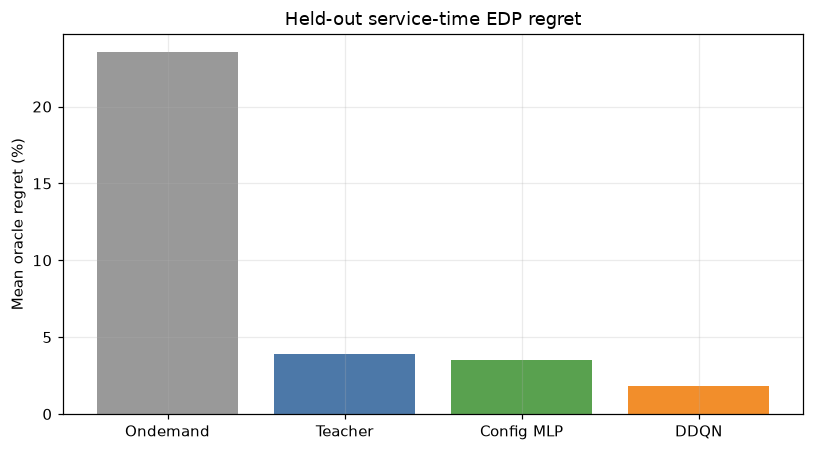

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
plot_df = master.set_index("policy").loc[
    ["Linux Ondemand", "PCHIP Teacher", "MLP Configuration Student", AGENT_LABEL]
]
ax.bar(
    ["Ondemand", "Teacher", "Config MLP", "DDQN"],
    100 * plot_df.mean_regret,
    color=["#999999", "#4c78a8", "#59a14f", "#f28e2b"],
)
ax.set_ylabel("Mean oracle regret (%)")
ax.set_title("Held-out service-time EDP regret")
fig.tight_layout()
fig.savefig(RESULTS / "configuration_policy_results.png", dpi=160)
plt.show()

## 10. Results and export

Exported tables retain held-out results. The portable NumPy weights contain the full-data controller, its feature statistics, and the ordered configuration actions.

In [12]:
idx = master.set_index("policy")
agent = idx.loc[AGENT_LABEL]
student = idx.loc["MLP Configuration Student"]
teacher = idx.loc["PCHIP Teacher"]
ondemand = idx.loc["Linux Ondemand"]
latency_ms = float(LATENCY.set_index("model").loc[AGENT_LABEL, "median_ms"])

print("FINAL RESULTS — CONFIGURATION-ONLY DDQN, SERVICE-TIME EDP")
print(
    f"Configuration teacher/student mean oracle regret: {100 * teacher.mean_regret:.2f}% / {100 * student.mean_regret:.2f}%."
)
print(
    f"DDQN mean oracle regret: {100 * agent.mean_regret:.2f}% (seed standard deviation: {100 * agent.seed_std_mean_regret:.3f} pp)."
)
print(f"Ondemand mean oracle regret: {100 * ondemand.mean_regret:.2f}%.")
print(
    f"DDQN mean per-state EDP reduction versus Ondemand: {-100 * agent.mean_delta_vs_ondemand:.2f}%."
)
print(
    f"DDQN beats Ondemand in {100 * agent.better_than_ondemand:.1f}% of held-out state/seed evaluations."
)
print(
    f"DDQN controller: {DEPLOY_NET.n_params:,} parameters; median inference latency: {latency_ms:.4f} ms."
)
print("Offline one-step configuration policy learning; gamma=0. EDP units: W·ms².")

frames = {
    "configuration_summary": CONFIG_SUMMARY,
    "configuration_folds": CONFIG_LOOCV,
    "agent_per_state_seed": RL_LOOCV,
    "master_results": master,
    "latency": LATENCY,
    "evaluation_table": TABLE,
    "states": STATES,
}
for name, frame in frames.items():
    frame.to_csv(RESULTS / f"{name}.csv", index=False)

# Store portable weights rather than pickled notebook-defined network classes.
weights = {
    "state_mean": DEPLOY_SURFACE.mu,
    "state_std": DEPLOY_SURFACE.sd,
    "sampling_rates_us": SR_ARR,
    "thresholds_pct": THR_ARR,
}
for name, network in [("trunk", DEPLOY_NET.trunk), ("head", DEPLOY_NET.head)]:
    for layer, (weight, bias) in enumerate(zip(network.W, network.b)):
        weights[f"{name}_W{layer}"] = weight
        weights[f"{name}_b{layer}"] = bias
np.savez(RESULTS / "configuration_only_ddqn_weights.npz", **weights)

import json, platform

run_metadata = {
    "agent_type": "DDQN",
    "action": ["sampling_rate_us", "threshold_pct"],
    "state_features": ["rho", "log10(1-rho)"],
    "gamma": CFG_.gamma,
    "controller_parameters": DEPLOY_NET.n_params,
    "agent_metrics": AGENT_METRICS,
    "raw_rows": len(raw),
    "usable_runs": len(runs),
    "configuration_cells": len(TABLE),
    "seeds": list(CFG_.rl_seeds),
    "data_source": DATA_SOURCE,
    "data_sha256": DATA_SHA256,
    "python_version": platform.python_version(),
}
(RESULTS / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))
print(f"\nResult tables and configuration-only weights saved in {RESULTS}.")

FINAL RESULTS — CONFIGURATION-ONLY DDQN, SERVICE-TIME EDP
Configuration teacher/student mean oracle regret: 3.89% / 3.54%.
DDQN mean oracle regret: 1.79% (seed standard deviation: 0.164 pp).
Ondemand mean oracle regret: 23.53%.
DDQN mean per-state EDP reduction versus Ondemand: 16.97%.
DDQN beats Ondemand in 100.0% of held-out state/seed evaluations.
DDQN controller: 4,946 parameters; median inference latency: 0.0698 ms.
Offline one-step configuration policy learning; gamma=0. EDP units: W·ms².

Result tables and configuration-only weights saved in results_x86_service_time_edp_config_only.
